# 01 — Quick checks on the 300 pilot questions (Plan Step 1)

**Goal:** before scaling to 1,000 questions, check that Lift is not just relevance under another name.

**Input:** the signals file named by `SIGNALS_FILE` in the setup cell below, in your data folder (`data\` on the laptop, Drive on Colab). The default is `halt_rag_w23_signals.csv` (the 2023 collection), written by the last cell of `notebooks/03_signals_w23.ipynb`.
If it is missing, run that notebook to the end first. Set `SIGNALS_FILE = "signals_v5"` to reproduce the old pilot numbers instead.

**What this notebook reports**
1. How closely the six signals move together (Spearman).
2. Each signal's own AUROC against the label, and against popularity (head vs tail).
3. Lift vs relevance: correlation, and whether Lift adds anything on top of relevance.
4. AUROC inside head only and inside tail only.
5. The Step 1 decision.

In [1]:
# ── Setup: works on a laptop (VS Code) and on Colab ───────────────────────
import os, sys, subprocess
ON_COLAB = "google.colab" in sys.modules
if ON_COLAB:
    # Colab: get the code from GitHub (push your latest commit first) and mount Drive
    REPO, BRANCH = "/content/HALT-RAG", "lift_signal"
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", "-q", "-b", BRANCH,
                        "https://github.com/Shaithra2107/HALT-RAG", REPO], check=True)
    else:
        subprocess.run(["git", "-C", REPO, "pull", "-q"], check=True)
    from google.colab import drive
    drive.mount("/content/drive")
else:
    # laptop: this notebook sits in <repo>/notebooks, so the repo is one level up
    REPO = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, os.path.join(REPO, "src"))

from halt_rag.config import load_config, data_path, data_dir
cfg = load_config(os.path.join(REPO, "config.yaml"))
print("running on:", "Colab" if ON_COLAB else "laptop", "| data folder:", data_dir(cfg))

# ── The one setting in this notebook ──────────────────────────────────────
# Which signals file to read, as a key in config.yaml's `paths:` block.
#   "signals_w23" = the 2023 collection  (written by notebooks/03_signals_w23.ipynb)
#   "signals_v5"  = the old pilot run    (written by HALT_RAG_v5_signals.ipynb)
# The results file is named after it, so the two runs never overwrite each other.
SIGNALS_FILE = "signals_w23"
print("signals file:", SIGNALS_FILE, "->", os.path.basename(data_path(cfg, SIGNALS_FILE)))

running on: laptop | data folder: E:\shaithu\4th Year\IRP\halt-rag-repo\HALT-RAG\data
signals file: signals_w23 -> halt_rag_w23_signals.csv


In [2]:
import numpy as np, pandas as pd, json
from halt_rag.signals import SIGNALS
from halt_rag.eval.metrics import signal_table, within_band_auroc, correlation_matrix, auroc_ci

path = data_path(cfg, SIGNALS_FILE)
assert os.path.exists(path), (
    f"Not found: {path}\nRun notebooks/03_signals_w23.ipynb to the end first "
    f"(or set SIGNALS_FILE = 'signals_v5' for the pilot file).")
df = pd.read_csv(path)
print(f"{len(df)} rows | columns: {list(df.columns)}")

signals = [s for s in SIGNALS + ["cas_mean"] if s in df.columns]
targets = [t for t in ["y_judge", "y_cov", "y_gen"] if t in df.columns]
print("signals:", signals)
print("labels :", {t: f"{int(df[t].sum())}/{len(df)}" for t in targets})
print("bands  :", df["band"].value_counts().to_dict())

300 rows | columns: ['question', 'answers_list', 'band', 'wiki_title', 'm2_status', 'm2_match', 'm3_covered', 'answer_string_match', 'passage_1', 'title_1', 'passage_2', 'title_2', 'passage_3', 'title_3', 'passage_4', 'title_4', 'passage_5', 'title_5', 'gold_answers', 'evidence_label', 'evidence_reason', 'm2_match_v5', 'm2_status_v5', 's_uri', 'qid', 'm2_status_w23', 'match_method_w23', 'lift', 'relevance', 'consistency', 'rand_mu', 'rand_sd', 'ret_idx', 'kw_coverage', 'clarity', 'cas', 'cas_mean', 'cas_soft', 'answers', 'gen_ctx', 'y_gen', 'y_judge', 'y_cov', 'is_tail', 'evaluable', 'noise_ctrl']
signals: ['lift', 'relevance', 'consistency', 'kw_coverage', 'clarity', 'cas', 'cas_mean']
labels : {'y_judge': '214/300', 'y_cov': '218/300', 'y_gen': '179/300'}
bands  : {'tail': 150, 'head': 150}


## Sanity: Lift recomputed with ε
`lift = (relevance − rand_mu) / max(rand_sd, ε)`. Should match the stored Lift (rand_sd is never near 0 in the pilot).

In [3]:
eps = cfg["signals"]["lift_eps"]
lift_eps = (df["relevance"] - df["rand_mu"]) / np.maximum(df["rand_sd"], eps)
print("max |difference| vs stored lift:", float((lift_eps - df["lift"]).abs().max()))
print("smallest rand_sd:", float(df["rand_sd"].min()))

max |difference| vs stored lift: 0.0
smallest rand_sd: 0.07017248868942261


## 1. How closely the signals move together (Spearman)

In [4]:
corr = correlation_matrix(df, signals)
display(corr.round(2).style.background_gradient(cmap="RdBu_r", vmin=-1, vmax=1))

,lift,relevance,consistency,kw_coverage,clarity,cas,cas_mean
lift,1.000000,0.740000,0.630000,0.120000,-0.180000,0.050000,0.160000
relevance,0.740000,1.000000,0.820000,0.170000,-0.220000,0.190000,0.330000
consistency,0.630000,0.820000,1.000000,0.050000,-0.200000,0.030000,0.230000
kw_coverage,0.120000,0.170000,0.050000,1.000000,-0.200000,0.250000,0.240000
clarity,-0.180000,-0.220000,-0.200000,-0.200000,1.000000,-0.170000,-0.160000
cas,0.050000,0.190000,0.030000,0.250000,-0.170000,1.000000,0.510000
cas_mean,0.160000,0.330000,0.230000,0.240000,-0.160000,0.510000,1.000000


## 2. Each signal on its own
`auroc_label` = how well it separates good from bad passage sets.
`auroc_popularity` = how well it separates head from tail.
`popularity_detector = True` means it tracks popularity more than the label.

Scopes: **all 300**, and **evaluable** (subject page found, so the label means something).

In [5]:
n_boot, seed = cfg["eval"]["n_bootstrap"], cfg["seed"]
scopes = {"all": df}
# The 2023 status column. "found" = answer on the subject page, "answer_not_on_page"
# = page found but the answer is not on it. Both mean the page WAS found, so the
# label means something. Only "page_missing" is dropped.
if "m2_status_w23" in df.columns:
    scopes["evaluable"] = df[df["m2_status_w23"].isin(["found", "answer_not_on_page"])]
    print("evaluable scope from: m2_status_w23 (found / answer_not_on_page)")
else:
    print("no m2_status_w23 column -> 'evaluable' scope skipped")
tables = {}
for scope, d in scopes.items():
    for t in targets:
        tab = signal_table(d, signals, t, n_boot=n_boot, seed=seed)
        tables[f"{scope}|{t}"] = tab
        print(f"\n=== scope={scope} (n={len(d)}) | label={t} (pos={int(d[t].sum())}) ===")
        display(tab.round(3))

evaluable scope from: m2_status_w23 (found / answer_not_on_page)



=== scope=all (n=300) | label=y_judge (pos=214) ===


,auroc_label,label_low,label_high,auprc_label,auroc_popularity,pop_low,pop_high,popularity_detector
signal,,,,,,,,
lift,0.630,0.557,0.698,0.801,0.611,0.548,0.676,False
relevance,0.628,0.556,0.699,0.795,0.666,0.603,0.728,True
consistency,0.541,0.465,0.609,0.745,0.662,0.596,0.725,True
kw_coverage,0.601,0.530,0.676,0.747,0.666,0.605,0.723,True
clarity,0.466,0.394,0.543,0.699,0.278,0.219,0.338,True
cas,0.804,0.744,0.861,0.867,0.560,0.490,0.625,False
cas_mean,0.613,0.546,0.680,0.800,0.655,0.594,0.716,True



=== scope=all (n=300) | label=y_cov (pos=218) ===


,auroc_label,label_low,label_high,auprc_label,auroc_popularity,pop_low,pop_high,popularity_detector
signal,,,,,,,,
lift,0.658,0.585,0.725,0.817,0.611,0.548,0.676,False
relevance,0.640,0.564,0.712,0.808,0.666,0.603,0.728,True
consistency,0.551,0.476,0.621,0.759,0.662,0.596,0.725,True
kw_coverage,0.617,0.541,0.685,0.777,0.666,0.605,0.723,True
clarity,0.440,0.364,0.521,0.702,0.278,0.219,0.338,True
cas,0.782,0.722,0.837,0.896,0.560,0.490,0.625,False
cas_mean,0.643,0.577,0.708,0.827,0.655,0.594,0.716,True



=== scope=all (n=300) | label=y_gen (pos=179) ===


... (3 outputs left out)


=== scope=evaluable (n=299) | label=y_cov (pos=217) ===


,auroc_label,label_low,label_high,auprc_label,auroc_popularity,pop_low,pop_high,popularity_detector
signal,,,,,,,,
lift,0.660,0.588,0.729,0.817,0.609,0.542,0.672,False
relevance,0.641,0.563,0.710,0.808,0.666,0.603,0.729,True
consistency,0.551,0.478,0.621,0.758,0.662,0.598,0.722,True
kw_coverage,0.620,0.546,0.687,0.777,0.664,0.603,0.722,True
clarity,0.440,0.368,0.515,0.701,0.278,0.222,0.337,True
cas,0.785,0.725,0.840,0.896,0.557,0.486,0.624,False
cas_mean,0.646,0.575,0.715,0.828,0.653,0.589,0.712,True



=== scope=evaluable (n=299) | label=y_gen (pos=179) ===


,auroc_label,label_low,label_high,auprc_label,auroc_popularity,pop_low,pop_high,popularity_detector
signal,,,,,,,,
lift,0.606,0.542,0.669,0.698,0.609,0.542,0.672,True
relevance,0.573,0.509,0.638,0.664,0.666,0.603,0.729,True
consistency,0.501,0.433,0.565,0.593,0.662,0.598,0.722,True
kw_coverage,0.528,0.462,0.596,0.596,0.664,0.603,0.722,True
clarity,0.536,0.464,0.605,0.623,0.278,0.222,0.337,True
cas,0.709,0.650,0.769,0.757,0.557,0.486,0.624,False
cas_mean,0.488,0.425,0.557,0.617,0.653,0.589,0.712,True


## 3. Lift vs relevance — is Lift something new?

corr(lift, relevance): Spearman 0.740 | Pearson 0.760


,relevance_only,relevance+lift,gain
label,,,
y_judge,0.625,0.633,0.008
y_cov,0.627,0.656,0.028
y_gen,0.566,0.588,0.022


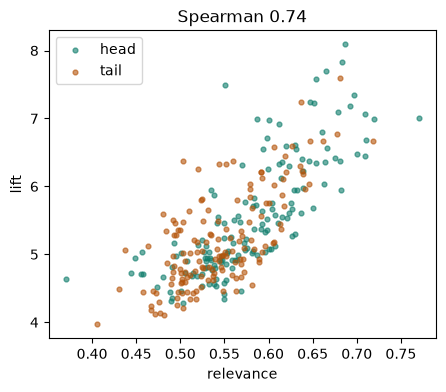

In [6]:
from scipy.stats import spearmanr, pearsonr
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

rho = spearmanr(df["lift"], df["relevance"]).correlation
r   = pearsonr(df["lift"], df["relevance"])[0]
print(f"corr(lift, relevance): Spearman {rho:.3f} | Pearson {r:.3f}")

def oof_auc(cols, target, d):
    """Out-of-fold AUROC of a logistic regression on these columns."""
    cv = StratifiedKFold(5, shuffle=True, random_state=seed)
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    p = cross_val_predict(m, d[cols], d[target], cv=cv, method="predict_proba")[:, 1]
    return auroc_ci(d[target], p, n_boot, seed=seed)

added = []
for t in targets:
    a_rel = oof_auc(["relevance"], t, df)
    a_both = oof_auc(["relevance", "lift"], t, df)
    added.append({"label": t, "relevance_only": a_rel[0], "relevance+lift": a_both[0],
                  "gain": a_both[0] - a_rel[0]})
added = pd.DataFrame(added).set_index("label")
display(added.round(3))

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(5, 4))
for band, c in [("head", "#0E7C6B"), ("tail", "#B45309")]:
    s = df[df["band"] == band]
    ax.scatter(s["relevance"], s["lift"], s=12, alpha=.6, label=band, color=c)
ax.set_xlabel("relevance"); ax.set_ylabel("lift"); ax.legend(); ax.set_title(f"Spearman {rho:.2f}")
plt.show()

## 4. Inside head only, and inside tail only

In [7]:
wb = {t: within_band_auroc(df, signals, t, n_boot=n_boot, seed=seed) for t in targets}
for t, tab in wb.items():
    print(f"\n=== label={t} ==="); display(tab.round(3))


=== label=y_judge ===


auroc           low          high       
band          head   tail   head   tail   head   tail
signal                                               
cas          0.769  0.852  0.684  0.771  0.853  0.919
cas_mean     0.664  0.611  0.570  0.501  0.750  0.715
clarity      0.441  0.490  0.330  0.389  0.557  0.591
consistency  0.562  0.557  0.461  0.449  0.655  0.657
kw_coverage  0.554  0.713  0.453  0.606  0.653  0.815
lift         0.601  0.698  0.506  0.594  0.689  0.798
relevance    0.618  0.712  0.519  0.612  0.708  0.809


=== label=y_cov ===


auroc           low          high       
band          head   tail   head   tail   head   tail
signal                                               
cas          0.803  0.742  0.728  0.646  0.877  0.830
cas_mean     0.710  0.587  0.619  0.483  0.801  0.686
clarity      0.425  0.495  0.304  0.394  0.545  0.593
consistency  0.542  0.567  0.440  0.467  0.643  0.666
kw_coverage  0.594  0.657  0.494  0.554  0.693  0.757
lift         0.601  0.726  0.497  0.625  0.703  0.818
relevance    0.603  0.705  0.501  0.604  0.703  0.799


=== label=y_gen ===


auroc           low          high       
band          head   tail   head   tail   head   tail
signal                                               
cas          0.692  0.812  0.611  0.727  0.777  0.882
cas_mean     0.512  0.564  0.419  0.465  0.607  0.666
clarity      0.514  0.473  0.419  0.368  0.610  0.580
consistency  0.533  0.565  0.441  0.468  0.626  0.659
kw_coverage  0.514  0.671  0.428  0.567  0.603  0.774
lift         0.625  0.677  0.532  0.577  0.717  0.774
relevance    0.597  0.677  0.505  0.578  0.688  0.770

## 5. Step 1 decision
Rule: warn if corr(lift, relevance) > 0.9 **or** Lift adds no AUROC on top of relevance
(gain ≤ 0.01). Either one on its own is enough to change Lift's background sample
(hard negatives) before scaling up.

The rule used to need **both** halves. That was too soft: Lift can sit well below 0.9
correlation and still carry no extra information about the label, which is the thing
this check exists to catch.

In [8]:
alarm = cfg["eval"]["lift_relevance_alarm"]
main = targets[0]
gain = float(added.loc[main, "gain"])
too_close = bool(abs(rho) > alarm)      # bool(), so the saved JSON says true/false not 1.0/0.0
adds_nothing = bool(gain <= 0.01)
print(f"corr(lift, relevance) = {rho:.3f}  (alarm above {alarm})  -> {'FAIL' if too_close else 'ok'}")
print(f"AUROC gain from adding Lift ({main}) = {gain:+.3f}  (alarm at or below +0.010)"
      f"  -> {'FAIL' if adds_nothing else 'ok'}")

# Warn if EITHER half fires: both are ways of saying Lift is relevance again.
if too_close or adds_nothing:
    why = []
    if too_close:
        why.append(f"it moves with relevance (Spearman {rho:.3f})")
    if adds_nothing:
        why.append(f"it adds no AUROC on top of relevance ({gain:+.3f})")
    print("\nDECISION: Lift ≈ relevance, because " + " and ".join(why) + ".")
    print("Change the background sample (hard negatives) before scaling up.")
else:
    print("\nDECISION: Lift is distinct enough. Go ahead with Step 2 as planned.")

out = {"signals_file": SIGNALS_FILE, "signals_path": path,
       "corr_lift_relevance_spearman": float(rho), "corr_lift_relevance_pearson": float(r),
       "lift_gain": added.round(4).to_dict(),
       "decision": {"rule": "warn if gain <= 0.01 OR |spearman| > alarm",
                    "alarm": alarm, "too_close": too_close,
                    "adds_nothing": adds_nothing, "warn": too_close or adds_nothing},
       "signal_tables": {k: v.round(4).to_dict() for k, v in tables.items()}}
# the results file is named after SIGNALS_FILE, so a w23 run never overwrites the pilot one
tag = SIGNALS_FILE.replace("signals_", "")
res = data_path(cfg, f"step1_quick_checks_{tag}.json")
json.dump(out, open(res, "w"), indent=2, default=float)
print("saved", res)

corr(lift, relevance) = 0.740  (alarm above 0.9)  -> ok
AUROC gain from adding Lift (y_judge) = +0.008  (alarm at or below +0.010)  -> FAIL

DECISION: Lift ≈ relevance, because it adds no AUROC on top of relevance (+0.008).
Change the background sample (hard negatives) before scaling up.


saved E:\shaithu\4th Year\IRP\halt-rag-repo\HALT-RAG\data\step1_quick_checks_w23.json
